# Classificação contextual de despesas

**Pergunta:** um modelo de aprendizado de máquina consegue sugerir a categoria certa de um gasto do cartão, inclusive de estabelecimentos que as regras do app não reconhecem?

**Hipóteses:**

1. Os modelos (Regressão Logística e Random Forest) ficam acima de um chute ingênuo (sempre a categoria mais comum).
2. Regras + modelo (o modelo só onde as regras não reconhecem o nome) acerta mais que as regras sozinhas.
3. Quando os gastos têm um padrão de dia da semana (delivery no fim de semana, estacionamento em dia útil...), o modelo consegue usar esse contexto temporal e acerta mais com ele.
4. A confiança que o modelo dá às sugestões é calibrada o bastante para ser mostrada ao usuário.

**Dados:** 13 faturas 100% fictícias, criadas pelo `ferramentas/gerar_faturas_sinteticas.py` com um perfil de quem gasta mais com comida e transporte (nenhum estabelecimento ou valor copiado de faturas reais). A categoria certa de cada lançamento vem do gabarito do gerador. Nenhum dado real entra neste notebook.

**Atenção para a hipótese 3:** o padrão de dia da semana foi **colocado pelo gerador**, de propósito. O teste mostra se o método consegue aproveitar um padrão temporal quando ele existe; não mostra que pessoas reais têm esse padrão.

In [1]:
import importlib.util
import sys
from collections import Counter
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import softmax
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, GroupKFold

PASTA_PROJETO = Path.cwd().parent
sys.path.insert(0, str(PASTA_PROJETO / 'src'))

import fatura as ft
import modelo as ml
import rotulos as rt

PASTA_SINTETICAS = PASTA_PROJETO / 'faturas_sinteticas'
SEMENTE = 2026
DOBRAS = 5
pd.set_option('display.width', 160)

# Na calibração (seção 11), algumas divisões internas por estabelecimento ficam sem nenhum lançamento de uma
# categoria pequena (8 de 9 categorias no treino). O scikit-learn avisa isso a cada vez; o efeito já aparece nas
# medidas (a categoria que faltou recebe probabilidade baixa), então o aviso repetido é silenciado.
import warnings
warnings.filterwarnings('ignore', message='Number of classes in training fold')

## 1. Dados

Se as faturas sintéticas não existem nesta cópia, o gerador as cria com a semente fixa: os arquivos saem sempre iguais.

In [2]:
if not (PASTA_SINTETICAS / 'gabarito.csv').exists():
    especificacao = importlib.util.spec_from_file_location('gerador', PASTA_PROJETO / 'ferramentas' / 'gerar_faturas_sinteticas.py')
    gerador = importlib.util.module_from_spec(especificacao)
    especificacao.loader.exec_module(gerador)
    gerador.gravar(gerador.gerar(13, SEMENTE, date(2025, 10, 25)), PASTA_SINTETICAS)

df_gabarito = pd.read_csv(PASTA_SINTETICAS / 'gabarito.csv')
print(len(df_gabarito), 'lançamentos no gabarito')

602 lançamentos no gabarito


Cada fatura passa pelo próprio app (`montar_fatura`): assim o notebook vê os lançamentos exatamente como o app vê, inclusive a categoria que as **regras** dariam. Ficam só os lançamentos que o app deixa rotular (sem pagamento, saldo anterior, juros/multas/IOF e estornos). A ligação com o gabarito é pela ordem das linhas do CSV, que é a mesma nos dois arquivos (conferida abaixo).

In [3]:
partes = []
for arquivo in sorted((PASTA_SINTETICAS / 'faturas').glob('*.csv')):
    df_csv = ft.ler_csv(arquivo.read_bytes())
    gabarito_da_fatura = df_gabarito[df_gabarito['fatura'] == arquivo.name].reset_index(drop=True)
    # Trava: a ligação pela ordem só vale se os títulos baterem linha a linha.
    assert list(df_csv['descricao']) == list(gabarito_da_fatura['title'].str.strip()), arquivo.name
    df_csv['categoria_certa'] = gabarito_da_fatura['categoria_certa'].to_numpy()
    df_fatura = ft.montar_fatura(df_csv.drop(columns='categoria_certa'), {})
    df_fatura = df_fatura.merge(
          df_csv[['linha', 'categoria_certa']]
        , on='linha'
        , how='left'
        , validate='one_to_one'
    )
    df_fatura = df_fatura[rt.rotulavel(df_fatura)].copy()
    df_fatura['fatura'] = arquivo.name
    df_fatura['vencimento'] = ft.vencimento_do_nome(arquivo.name)
    partes.append(df_fatura)

df_dados = pd.concat(partes, ignore_index=True)
df_dados = df_dados.rename(columns={'categoria': 'categoria_regras'})
print(len(df_dados), 'lançamentos rotuláveis em', df_dados['fatura'].nunique(), 'faturas e', df_dados['chave'].nunique(), 'estabelecimentos')

565 lançamentos rotuláveis em 13 faturas e 88 estabelecimentos


In [4]:
resumo_categorias = (
    df_dados
    .groupby('categoria_certa')
    .agg(
          lancamentos=('chave', 'size')
        , estabelecimentos=('chave', 'nunique')
    )
    .sort_values('lancamentos', ascending=False)
)
resumo_categorias

,lancamentos,estabelecimentos
categoria_certa,,
Transporte,172,15
Comida e bebida,135,21
Assinaturas,104,10
Compras,49,9
Casa e contas,31,5
Viagem,25,8
Saúde,23,6
Lazer,15,7
Jogos,11,7


As regras do app reconhecem parte dos nomes. Onde não reconhecem, o lançamento fica "A classificar": é ali que o modelo pode ajudar.

In [5]:
regras_certas = (df_dados['categoria_regras'] == df_dados['categoria_certa']).mean()
regras_sem_resposta = (df_dados['categoria_regras'] == ft.A_CLASSIFICAR).mean()
regras_erradas = ((df_dados['categoria_regras'] != df_dados['categoria_certa']) & (df_dados['categoria_regras'] != ft.A_CLASSIFICAR)).mean()
print(f'Regras certas: {regras_certas:.1%} | sem resposta (A classificar): {regras_sem_resposta:.1%} | erradas: {regras_erradas:.1%}')

desconhecidos = (
    df_dados[df_dados['categoria_regras'] == ft.A_CLASSIFICAR]
    .groupby('categoria_certa')['chave']
    .nunique()
    .rename('estabelecimentos_sem_regra')
)
desconhecidos

Regras certas: 73.6% | sem resposta (A classificar): 26.4% | erradas: 0.0%


categoria_certa
Assinaturas        3
Casa e contas      1
Comida e bebida    6
Compras            5
Jogos              3
Lazer              3
Saúde              1
Transporte         6
Viagem             3
Name: estabelecimentos_sem_regra, dtype: int64

## 2. Como avaliar sem se enganar

O mesmo estabelecimento aparece em vários meses com o mesmo nome. Se ele estiver no treino **e** no teste, o modelo "acerta" só porque decorou o nome, e a nota sai inflada. No uso real, o que importa é acertar estabelecimentos **novos**.

Por isso a validação cruzada é **agrupada por estabelecimento** (`GroupKFold`, 5 dobras): cada estabelecimento fica inteiro no treino ou inteiro no teste.

Métricas, sempre sobre as categorias que existem no gabarito daquele trecho:

- **F1-macro** (principal): média do F1 de cada categoria, então uma categoria pequena pesa tanto quanto uma grande;
- **precisão macro** e **recall macro**;
- média e desvio entre as 5 dobras.

In [6]:
grupos = df_dados['chave'].to_numpy()
y = df_dados['categoria_certa'].to_numpy()
CATEGORIAS_GABARITO = sorted(df_dados['categoria_certa'].unique())
divisao = GroupKFold(n_splits=DOBRAS)
dobras = list(divisao.split(df_dados, y, grupos))

for numero, (treino, teste) in enumerate(dobras, start=1):
    print(
          f'Dobra {numero}: treino {len(treino)} lançamentos / {len(set(grupos[treino]))} estabelecimentos'
        , f'| teste {len(teste)} / {len(set(grupos[teste]))}'
        , '| em comum:', len(set(grupos[treino]) & set(grupos[teste]))
    )

Dobra 1: treino 452 lançamentos / 74 estabelecimentos | teste 113 / 14 | em comum: 0
Dobra 2: treino 452 lançamentos / 70 estabelecimentos | teste 113 / 18 | em comum: 0
Dobra 3: treino 452 lançamentos / 70 estabelecimentos | teste 113 / 18 | em comum: 0
Dobra 4: treino 452 lançamentos / 69 estabelecimentos | teste 113 / 19 | em comum: 0
Dobra 5: treino 452 lançamentos / 69 estabelecimentos | teste 113 / 19 | em comum: 0


In [7]:
def medir(certo, previsto):
    # Média só sobre as categorias que existem no trecho avaliado: uma dobra sem nenhum lançamento de
    # "Jogos" não ganha um zero artificial para Jogos. "A classificar" previsto conta como erro.
    categorias = sorted(set(certo))
    return {
          'f1_macro': f1_score(certo, previsto, labels=categorias, average='macro', zero_division=0)
        , 'precisao_macro': precision_score(certo, previsto, labels=categorias, average='macro', zero_division=0)
        , 'recall_macro': recall_score(certo, previsto, labels=categorias, average='macro', zero_division=0)
        , 'acuracia': float(np.mean(np.asarray(certo) == np.asarray(previsto)))
    }


def medir_por_dobra(previsto):
    resultados = []
    for treino, teste in dobras:
        resultados.append(medir(y[teste], previsto[teste]))
    return pd.DataFrame(resultados)


def combinar_com_regras(previsto):
    # O que o app faz: usa as regras quando elas reconhecem o nome e o modelo só no que ficou "A classificar".
    return np.where(previsto_regras == ft.A_CLASSIFICAR, previsto, previsto_regras)

## 3. Bases de comparação

- **Classe mais comum:** sempre a categoria mais frequente no treino da dobra.
- **Regras do app:** a categoria das regras; quando elas não reconhecem o nome ("A classificar"), conta como erro, porque o usuário fica sem resposta.

In [8]:
previsto_comum = np.empty(len(y), dtype=object)
for treino, teste in dobras:
    previsto_comum[teste] = pd.Series(y[treino]).mode()[0]
previsto_regras = df_dados['categoria_regras'].to_numpy()

comparacao = {}
comparacao['Classe mais comum'] = medir_por_dobra(previsto_comum)
comparacao['Regras do app'] = medir_por_dobra(previsto_regras)

## 4. Modelos (exploração)

Representação de cada lançamento (a mesma do app, em `src/modelo.py`):

- **texto:** TF-IDF de pedaços de 2 a 4 letras do nome normalizado ("posto", "farma", "ifd*"), o que funciona também com nomes nunca vistos;
- **valor** em escala logarítmica;
- **histórico do estabelecimento:** em que fração das faturas ele aparece e se o valor se repete (assinatura cobra sempre o mesmo valor);
- **parcela** (sim ou não);
- **contexto temporal:** dia da semana e posição no ciclo da fatura (testado com e sem).

Quatro configurações (Regressão Logística e Random Forest, com e sem contexto temporal). Em cada dobra externa, uma busca com validação **interna** agrupada por estabelecimento escolhe o `C` da Regressão Logística ou o `min_samples_leaf` da Random Forest só com os dados de treino daquela dobra.

**Cuidado ao ler esta seção:** comparar as quatro configurações pelas dobras externas e ficar com a melhor é escolher olhando o teste, e a nota da escolhida sai otimista. Por isso a seção 5 refaz a escolha inteira por dentro das dobras; **a nota do procedimento é a da seção 5**.

In [9]:
# O que o histórico diz de cada estabelecimento (frequência nas faturas e se o valor se repete) usa só as
# faturas, nunca as categorias: não vaza o gabarito, e o app tem a mesma informação.
FATURAS_DO_HISTORICO = []
for nome_fatura, df_uma_fatura in df_dados.groupby('fatura'):
    FATURAS_DO_HISTORICO.append({'fatura': df_uma_fatura})
HISTORICO = ml.historico_estabelecimentos(FATURAS_DO_HISTORICO)

GRADES = {
      ml.LOGISTICA: {'modelo__C': [0.1, 1.0, 10.0, 100.0]}
    , ml.FLORESTA: {'modelo__min_samples_leaf': [1, 2, 5]}
}


def avaliar(tipo, usar_tempo):
    previsto = np.empty(len(y), dtype=object)
    probabilidades = np.zeros((len(y), len(CATEGORIAS_GABARITO)))
    escolhidos = []
    for treino, teste in dobras:
        df_treino = df_dados.iloc[treino]
        df_teste = df_dados.iloc[teste]
        atributos_treino = ml.preparar(df_treino, HISTORICO)
        atributos_teste = ml.preparar(df_teste, HISTORICO)
        busca = GridSearchCV(
              ml.montar_pipeline(tipo, usar_tempo=usar_tempo)
            , GRADES[tipo]
            , scoring='f1_macro'
            , cv=GroupKFold(n_splits=3)
        )
        busca.fit(atributos_treino, y[treino], groups=grupos[treino])
        escolhidos.append(busca.best_params_)
        previsto[teste] = busca.predict(atributos_teste)
        classes = list(busca.best_estimator_.named_steps['modelo'].classes_)
        probabilidade_dobra = busca.predict_proba(atributos_teste)
        for coluna, categoria in enumerate(classes):
            probabilidades[teste, CATEGORIAS_GABARITO.index(categoria)] = probabilidade_dobra[:, coluna]
    return previsto, probabilidades, escolhidos

In [10]:
resultados = {}
for tipo in [ml.LOGISTICA, ml.FLORESTA]:
    for usar_tempo in [True, False]:
        nome = tipo + (' (com contexto temporal)' if usar_tempo else ' (sem contexto temporal)')
        resultados[nome] = avaliar(tipo, usar_tempo)
        comparacao[nome] = medir_por_dobra(resultados[nome][0])
        comparacao['Regras + ' + nome] = medir_por_dobra(combinar_com_regras(resultados[nome][0]))
        print(nome, '| hiperparâmetros escolhidos nas 5 dobras:', resultados[nome][2])

Regressão Logística (com contexto temporal) | hiperparâmetros escolhidos nas 5 dobras: [{'modelo__C': 10.0}, {'modelo__C': 10.0}, {'modelo__C': 100.0}, {'modelo__C': 1.0}, {'modelo__C': 0.1}]


Regressão Logística (sem contexto temporal) | hiperparâmetros escolhidos nas 5 dobras: [{'modelo__C': 10.0}, {'modelo__C': 100.0}, {'modelo__C': 100.0}, {'modelo__C': 10.0}, {'modelo__C': 1.0}]


Random Forest (com contexto temporal) | hiperparâmetros escolhidos nas 5 dobras: [{'modelo__min_samples_leaf': 2}, {'modelo__min_samples_leaf': 1}, {'modelo__min_samples_leaf': 2}, {'modelo__min_samples_leaf': 5}, {'modelo__min_samples_leaf': 1}]


Random Forest (sem contexto temporal) | hiperparâmetros escolhidos nas 5 dobras: [{'modelo__min_samples_leaf': 2}, {'modelo__min_samples_leaf': 1}, {'modelo__min_samples_leaf': 5}, {'modelo__min_samples_leaf': 5}, {'modelo__min_samples_leaf': 2}]


## 5. Seleção totalmente aninhada (a nota do procedimento)

Aqui **tudo** é escolhido só com os dados de treino de cada dobra externa: o tipo de modelo, o uso ou não do contexto temporal e o hiperparâmetro. Para cada uma das 14 combinações, uma validação interna (3 dobras, agrupadas por estabelecimento) mede o F1-macro de regras + modelo; a melhor é treinada no treino inteiro da dobra e testada nos estabelecimentos que ela nunca viu. Esta é a estimativa honesta do que o procedimento entrega.

(Código do teste de sanidade da seção.)

In [11]:
CONFIGURACOES = [(tipo, tempo, p) for tipo in [ml.LOGISTICA, ml.FLORESTA] for tempo in [True, False]
                 for p in (GRADES[tipo]['modelo__C'] if tipo == ml.LOGISTICA else GRADES[tipo]['modelo__min_samples_leaf'])]
def montar_configuracao(c):
    tipo, tempo, p = c
    return ml.montar_pipeline(tipo, usar_tempo=tempo, C=p) if tipo == ml.LOGISTICA else ml.montar_pipeline(tipo, usar_tempo=tempo, min_samples_leaf=p)
previsto_procedimento = np.empty(len(y), dtype=object)
escolhas_procedimento = []
for treino, teste in dobras:
    atributos_treino = ml.preparar(df_dados.iloc[treino], HISTORICO)
    regras_treino = previsto_regras[treino]
    melhor = None
    for c in CONFIGURACOES:
        notas = []
        for ti, va in GroupKFold(n_splits=3).split(atributos_treino, y[treino], grupos[treino]):
            pipeline = montar_configuracao(c)
            pipeline.fit(atributos_treino.iloc[ti], y[treino][ti])
            combinado = np.where(regras_treino[va] == ft.A_CLASSIFICAR, pipeline.predict(atributos_treino.iloc[va]), regras_treino[va])
            notas.append(medir(y[treino][va], combinado)['f1_macro'])
        if melhor is None or np.mean(notas) > melhor[0]:
            melhor = (np.mean(notas), c)
    escolhas_procedimento.append(melhor[1])
    pipeline = montar_configuracao(melhor[1])
    pipeline.fit(atributos_treino, y[treino])
    previsto_procedimento[teste] = pipeline.predict(ml.preparar(df_dados.iloc[teste], HISTORICO))
nota = medir_por_dobra(np.where(previsto_regras == ft.A_CLASSIFICAR, previsto_procedimento, previsto_regras))['f1_macro']
print('Escolhas por dobra:', escolhas_procedimento)
print(f'Regras + modelo, seleção aninhada: {nota.mean():.3f} ± {nota.std():.3f}')

Escolhas por dobra: [('Regressão Logística', False, 100.0), ('Random Forest', True, 1), ('Random Forest', True, 1), ('Regressão Logística', False, 100.0), ('Regressão Logística', True, 0.1)]
Regras + modelo, seleção aninhada: 0.748 ± 0.171


**O que vai para o app:** o mesmo procedimento de escolha (as 14 combinações, validação em 3 dobras agrupadas por estabelecimento) aplicado agora a **todos** os dados, como se faz para o modelo final. As escolhas acima variam de dobra para dobra: com tão poucos estabelecimentos, várias configurações ficam praticamente empatadas. `src/modelo.py` guarda `TIPO_APP`, `TEMPO_APP` e `C_APP`; a trava abaixo falha se o app estiver com outra.

In [12]:
NOME_PROCEDIMENTO = 'Seleção aninhada (procedimento)'
comparacao[NOME_PROCEDIMENTO] = medir_por_dobra(previsto_procedimento)
comparacao['Regras + ' + NOME_PROCEDIMENTO] = medir_por_dobra(combinar_com_regras(previsto_procedimento))
print('Escolhas nas 5 dobras:', dict(Counter(escolhas_procedimento)))


def nota_da_configuracao(par):
    return -par[1]


atributos_todos = ml.preparar(df_dados, HISTORICO)
notas_finais = {}
for configuracao in CONFIGURACOES:
    notas = []
    for ti, va in GroupKFold(n_splits=3).split(atributos_todos, y, grupos):
        pipeline = montar_configuracao(configuracao)
        pipeline.fit(atributos_todos.iloc[ti], y[ti])
        combinado = np.where(previsto_regras[va] == ft.A_CLASSIFICAR, pipeline.predict(atributos_todos.iloc[va]), previsto_regras[va])
        notas.append(medir(y[va], combinado)['f1_macro'])
    notas_finais[configuracao] = np.mean(notas)
ESCOLHA_APP = max(notas_finais, key=notas_finais.get)
for configuracao, valor in sorted(notas_finais.items(), key=nota_da_configuracao)[:5]:
    print(f'{valor:.3f}', configuracao)
print('Escolhida para o app (todos os dados):', ESCOLHA_APP)
print('No app (src/modelo.py):', (ml.TIPO_APP, ml.TEMPO_APP, ml.C_APP))
assert (ml.TIPO_APP, ml.TEMPO_APP, ml.C_APP) == ESCOLHA_APP

Escolhas nas 5 dobras: {('Regressão Logística', False, 100.0): 2, ('Random Forest', True, 1): 2, ('Regressão Logística', True, 0.1): 1}


0.819 ('Regressão Logística', False, 100.0)
0.800 ('Regressão Logística', False, 10.0)
0.797 ('Random Forest', True, 1)
0.797 ('Random Forest', False, 1)
0.786 ('Regressão Logística', True, 10.0)
Escolhida para o app (todos os dados): ('Regressão Logística', False, 100.0)
No app (src/modelo.py): ('Regressão Logística', False, 100.0)


## 6. Resultados por lançamento

F1-macro, precisão e recall de cada abordagem: média ± desvio entre as 5 dobras (cada dobra com estabelecimentos que o modelo nunca viu). As linhas das quatro configurações da seção 4 são exploração (otimistas, ver aviso); a linha do procedimento é a estimativa honesta.

In [13]:
linhas_tabela = []
for nome, tabela in comparacao.items():
    linhas_tabela.append([
          nome
        , f"{tabela['f1_macro'].mean():.3f} ± {tabela['f1_macro'].std():.3f}"
        , f"{tabela['precisao_macro'].mean():.3f} ± {tabela['precisao_macro'].std():.3f}"
        , f"{tabela['recall_macro'].mean():.3f} ± {tabela['recall_macro'].std():.3f}"
        , f"{tabela['acuracia'].mean():.3f}"
    ])
tabela_resultados = pd.DataFrame(linhas_tabela, columns=['Abordagem', 'F1-macro', 'Precisão macro', 'Recall macro', 'Acurácia'])
tabela_resultados

,Abordagem,F1-macro,Precisão macro,Recall macro,Acurácia
0,Classe mais comum,0.047 ± 0.018,0.029 ± 0.013,0.136 ± 0.010,0.216
1,Regras do app,0.726 ± 0.114,0.814 ± 0.146,0.687 ± 0.103,0.736
2,Regressão Logística (com contexto temporal),0.433 ± 0.059,0.463 ± 0.082,0.500 ± 0.060,0.473
3,Regras + Regressão Logística (com contexto tem...,0.746 ± 0.144,0.743 ± 0.162,0.809 ± 0.123,0.865
4,Regressão Logística (sem contexto temporal),0.467 ± 0.080,0.519 ± 0.103,0.521 ± 0.046,0.497
5,Regras + Regressão Logística (sem contexto tem...,0.765 ± 0.127,0.790 ± 0.129,0.819 ± 0.114,0.878
6,Random Forest (com contexto temporal),0.450 ± 0.132,0.480 ± 0.142,0.478 ± 0.109,0.465
7,Regras + Random Forest (com contexto temporal),0.764 ± 0.154,0.798 ± 0.175,0.792 ± 0.121,0.835
8,Random Forest (sem contexto temporal),0.418 ± 0.120,0.454 ± 0.118,0.449 ± 0.089,0.469
9,Regras + Random Forest (sem contexto temporal),0.759 ± 0.160,0.783 ± 0.167,0.796 ± 0.126,0.855


**Regras + modelo contra regras sozinhas, dobra a dobra.** Nestes dados as regras nunca erram (os nomes foram criados assim) e "A classificar" conta como erro; então regras + modelo não pode acertar menos lançamentos que as regras. A pergunta é de quanto é o ganho e se ele aparece em todas as dobras.

In [14]:
diferencas = comparacao['Regras + ' + NOME_PROCEDIMENTO]['f1_macro'] - comparacao['Regras do app']['f1_macro']
print('Ganho de F1-macro por dobra:', [round(valor, 3) for valor in diferencas])
print(f'Média {diferencas.mean():+.3f} ± {diferencas.std():.3f}; positivo em {int((diferencas > 0).sum())} de {DOBRAS} dobras')

Ganho de F1-macro por dobra: [-0.177, 0.102, -0.052, 0.194, 0.043]
Média +0.022 ± 0.143; positivo em 3 de 5 dobras


## 7. Só onde as regras não sabem responder

O teste mais difícil: os lançamentos que as regras deixam em "A classificar". Aqui as regras acertam 0%, então qualquer acerto é ganho real do modelo.

In [15]:
sem_regra = previsto_regras == ft.A_CLASSIFICAR
linhas_tabela = []
todos = dict(resultados)
todos[NOME_PROCEDIMENTO] = (previsto_procedimento, None, None)
for nome, (previsto, probabilidades, escolhidos) in todos.items():
    medidas = medir(y[sem_regra], previsto[sem_regra])
    linhas_tabela.append([nome, sem_regra.sum(), f"{medidas['acuracia']:.3f}", f"{medidas['f1_macro']:.3f}"])
pd.DataFrame(linhas_tabela, columns=['Modelo', 'Lançamentos sem regra', 'Acurácia', 'F1-macro'])

,Modelo,Lançamentos sem regra,Acurácia,F1-macro
0,Regressão Logística (com contexto temporal),149,0.490,0.324
1,Regressão Logística (sem contexto temporal),149,0.537,0.340
2,Random Forest (com contexto temporal),149,0.376,0.229
3,Random Forest (sem contexto temporal),149,0.450,0.263
4,Seleção aninhada (procedimento),149,0.477,0.327


## 8. Por estabelecimento

Um estabelecimento frequente (o metrô, o mercado do bairro) pesa muito na conta por lançamento. Por estabelecimento, cada um conta uma vez: a categoria prevista é a mais votada entre os lançamentos dele.

In [16]:
def mais_votada(serie):
    return serie.mode()[0]


verdade_estabelecimento = df_dados.groupby('chave')['categoria_certa'].first()
linhas_tabela = []
for nome, (previsto, probabilidades, escolhidos) in todos.items():
    votos = (
        pd.DataFrame({'chave': grupos, 'previsto': previsto})
        .groupby('chave')['previsto']
        .agg(mais_votada)
    )
    medidas = medir(verdade_estabelecimento.loc[votos.index], votos)
    linhas_tabela.append([nome, len(votos), f"{medidas['f1_macro']:.3f}", f"{medidas['acuracia']:.3f}"])
pd.DataFrame(linhas_tabela, columns=['Modelo', 'Estabelecimentos', 'F1-macro', 'Acurácia'])

,Modelo,Estabelecimentos,F1-macro,Acurácia
0,Regressão Logística (com contexto temporal),88,0.397,0.466
1,Regressão Logística (sem contexto temporal),88,0.408,0.477
2,Random Forest (com contexto temporal),88,0.385,0.432
3,Random Forest (sem contexto temporal),88,0.368,0.409
4,Seleção aninhada (procedimento),88,0.393,0.432


## 9. Matriz de confusão

Regras + o procedimento da seção 5 (fora da dobra). Em cada linha, a categoria certa; em cada coluna, a prevista. Fora da diagonal estão os erros.

In [17]:
matriz = confusion_matrix(y, combinar_com_regras(previsto_procedimento), labels=CATEGORIAS_GABARITO)
pd.DataFrame(matriz, index=CATEGORIAS_GABARITO, columns=CATEGORIAS_GABARITO)

,Assinaturas,Casa e contas,Comida e bebida,Compras,Jogos,Lazer,Saúde,Transporte,Viagem
Assinaturas,93,0,0,0,0,0,0,11,0
Casa e contas,0,29,0,0,1,1,0,0,0
Comida e bebida,0,0,125,0,0,0,1,9,0
Compras,0,2,3,41,1,0,2,0,0
Jogos,0,0,0,2,9,0,0,0,0
Lazer,0,0,4,2,0,8,1,0,0
Saúde,0,0,1,0,0,0,22,0,0
Transporte,0,0,26,0,0,0,2,138,6
Viagem,0,0,0,0,0,2,0,1,22


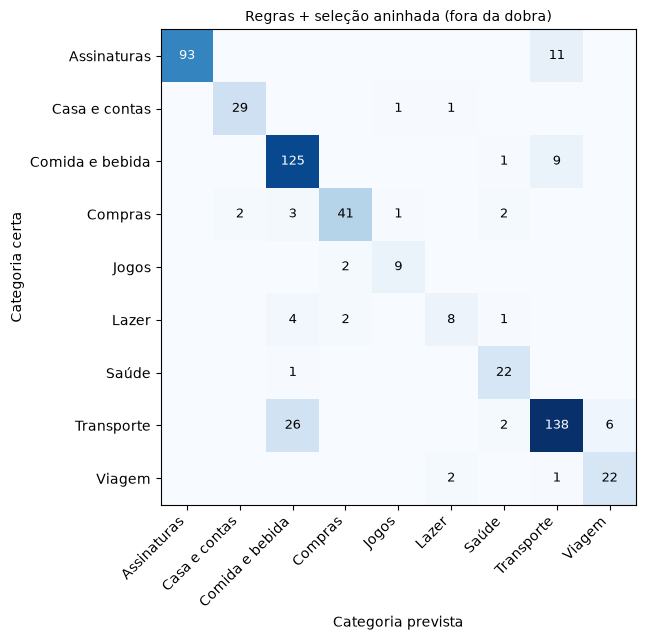

In [18]:
figura, eixo = plt.subplots(figsize=(8, 6.5))
eixo.imshow(matriz, cmap='Blues')
eixo.set_xticks(range(len(CATEGORIAS_GABARITO)))
eixo.set_yticks(range(len(CATEGORIAS_GABARITO)))
eixo.set_xticklabels(CATEGORIAS_GABARITO, rotation=45, ha='right')
eixo.set_yticklabels(CATEGORIAS_GABARITO)
for linha in range(len(CATEGORIAS_GABARITO)):
    for coluna in range(len(CATEGORIAS_GABARITO)):
        if matriz[linha, coluna] > 0:
            cor = 'white' if matriz[linha, coluna] > matriz.max() / 2 else 'black'
            eixo.text(coluna, linha, matriz[linha, coluna], ha='center', va='center', color=cor, fontsize=9)
eixo.set_xlabel('Categoria prevista')
eixo.set_ylabel('Categoria certa')
eixo.set_title('Regras + seleção aninhada (fora da dobra)', fontsize=10)
figura.tight_layout()
plt.show()

## 10. Contexto temporal ajuda? (hipótese 3)

Mesma comparação, com e sem dia da semana e posição no ciclo, dobra a dobra. O CSV do Nubank não traz horário, então não há hora nem sequência de compras dentro do dia. Lembrete: o padrão temporal destes dados foi colocado pelo gerador.

In [19]:
linhas_tabela = []
for tipo in [ml.LOGISTICA, ml.FLORESTA]:
    com_tempo = comparacao[tipo + ' (com contexto temporal)']['f1_macro']
    sem_tempo = comparacao[tipo + ' (sem contexto temporal)']['f1_macro']
    diferencas_tempo = com_tempo - sem_tempo
    linhas_tabela.append([
          tipo
        , f'{com_tempo.mean():.3f}'
        , f'{sem_tempo.mean():.3f}'
        , f'{diferencas_tempo.mean():+.3f} ± {diferencas_tempo.std():.3f}'
        , int((diferencas_tempo > 0).sum())
    ])
print('Dobras em que a seleção aninhada escolheu usar o tempo:', sum(1 for escolha in escolhas_procedimento if escolha[1]), 'de', DOBRAS)
pd.DataFrame(linhas_tabela, columns=['Modelo', 'F1 com tempo', 'F1 sem tempo', 'Diferença por dobra', 'Dobras em que ajudou (de 5)'])

Dobras em que a seleção aninhada escolheu usar o tempo: 3 de 5


,Modelo,F1 com tempo,F1 sem tempo,Diferença por dobra,Dobras em que ajudou (de 5)
0,Regressão Logística,0.433,0.467,-0.034 ± 0.069,2
1,Random Forest,0.450,0.418,+0.032 ± 0.091,3


## 11. A confiança do modelo é calibrada? (hipótese 4)

O app mostra a confiança de cada sugestão. Ela só é útil se for honesta: entre as sugestões dadas com ~80% de confiança, ~80% devem estar certas.

Medidas sobre as probabilidades fora da dobra:

- **ECE** (erro de calibração esperado): diferença média entre confiança e acerto, por faixa de confiança (0 = perfeito);
- **Brier**: erro quadrático das probabilidades (menor é melhor).

Primeiro as quatro configurações da seção 4, sem nenhuma correção.

In [20]:
def calibracao(previsto, probabilidades, faixas=10):
    confianca = probabilidades.max(axis=1)
    acerto = (previsto == y).astype(float)
    limites = np.linspace(0, 1, faixas + 1)
    linhas_faixa = []
    ece = 0.0
    for inicio, fim in zip(limites[:-1], limites[1:]):
        na_faixa = (confianca > inicio) & (confianca <= fim)
        if na_faixa.sum() == 0:
            continue
        ece = ece + na_faixa.mean() * abs(acerto[na_faixa].mean() - confianca[na_faixa].mean())
        linhas_faixa.append([confianca[na_faixa].mean(), acerto[na_faixa].mean(), int(na_faixa.sum())])
    verdade = np.zeros_like(probabilidades)
    for posicao, categoria in enumerate(y):
        verdade[posicao, CATEGORIAS_GABARITO.index(categoria)] = 1
    brier = float(np.mean(np.sum((probabilidades - verdade) ** 2, axis=1)))
    return ece, brier, pd.DataFrame(linhas_faixa, columns=['confianca_media', 'acerto', 'lancamentos'])


faixas_por_modelo = {}
linhas_tabela = []
for nome, (previsto, probabilidades, escolhidos) in resultados.items():
    ece, brier, faixas = calibracao(previsto, probabilidades)
    faixas_por_modelo[nome] = faixas
    linhas_tabela.append([nome, f'{ece:.3f}', f'{brier:.3f}', f'{probabilidades.max(axis=1).mean():.3f}', f'{(previsto == y).mean():.3f}'])
pd.DataFrame(linhas_tabela, columns=['Modelo', 'ECE', 'Brier', 'Confiança média', 'Acurácia'])

,Modelo,ECE,Brier,Confiança média,Acurácia
0,Regressão Logística (com contexto temporal),0.221,0.777,0.599,0.473
1,Regressão Logística (sem contexto temporal),0.185,0.744,0.673,0.497
2,Random Forest (com contexto temporal),0.208,0.704,0.413,0.465
3,Random Forest (sem contexto temporal),0.217,0.698,0.391,0.469


Três correções testadas na configuração do app, todas aprendidas com estabelecimentos que o modelo não viu no treino (validação interna agrupada por estabelecimento, dentro de cada dobra):

- **sigmoide (Platt), modo conjunto:** padrão do scikit-learn; o modelo final é a média de 3 modelos treinados com 2/3 dos dados cada;
- **sigmoide, modo único (`ensemble=False`):** um modelo treinado com todo o treino da dobra e a curva sigmoide aprendida nas previsões da validação interna;
- **temperatura:** divide todas as pontuações do modelo por um único número T; não muda a categoria prevista.

In [21]:
TIPO_ESCOLHIDO, TEMPO_ESCOLHIDO, PARAMETRO_ESCOLHIDO = ESCOLHA_APP
NOME_APP = 'Configuração do app'


def prever_calibrado(variante):
    previsto = np.empty(len(y), dtype=object)
    probabilidades = np.zeros((len(y), len(CATEGORIAS_GABARITO)))
    temperaturas = []
    for treino, teste in dobras:
        atributos_treino = ml.preparar(df_dados.iloc[treino], HISTORICO)
        atributos_teste = ml.preparar(df_dados.iloc[teste], HISTORICO)
        pipeline = montar_configuracao(ESCOLHA_APP)
        divisao_interna = list(GroupKFold(n_splits=3).split(atributos_treino, y[treino], grupos[treino]))
        if variante == 'sem calibração':
            pipeline.fit(atributos_treino, y[treino])
            classes = list(pipeline.named_steps['modelo'].classes_)
            probabilidade_dobra = pipeline.predict_proba(atributos_teste)
        elif variante == 'temperatura':
            temperatura = ml.temperatura_por_validacao(TIPO_ESCOLHIDO, atributos_treino, y[treino], grupos[treino], usar_tempo=TEMPO_ESCOLHIDO, C=PARAMETRO_ESCOLHIDO)
            temperaturas.append(round(temperatura, 2))
            pipeline.fit(atributos_treino, y[treino])
            classes = CATEGORIAS_GABARITO
            probabilidade_dobra = softmax(ml.pontuacoes(pipeline, atributos_teste, CATEGORIAS_GABARITO) / temperatura, axis=1)
        else:
            calibrado = CalibratedClassifierCV(pipeline, method='sigmoid', cv=divisao_interna, ensemble=(variante == 'sigmoide, modo conjunto'))
            calibrado.fit(atributos_treino, y[treino])
            classes = list(calibrado.classes_)
            probabilidade_dobra = calibrado.predict_proba(atributos_teste)
        for coluna, categoria in enumerate(classes):
            probabilidades[teste, CATEGORIAS_GABARITO.index(categoria)] = probabilidade_dobra[:, coluna]
        previsto[teste] = np.array(CATEGORIAS_GABARITO)[probabilidades[teste].argmax(axis=1)]
    return previsto, probabilidades, temperaturas


if TIPO_ESCOLHIDO != ml.LOGISTICA:
    print('A temperatura só se aplica à Regressão Logística; ela fica de fora.')
VARIANTES = ['sem calibração', 'sigmoide, modo conjunto', 'sigmoide, modo único']
if TIPO_ESCOLHIDO == ml.LOGISTICA:
    VARIANTES.append('temperatura')
calibradas = {}
linhas_tabela = []
for variante in VARIANTES:
    previsto, probabilidades, temperaturas = prever_calibrado(variante)
    calibradas[variante] = (previsto, probabilidades)
    ece, brier, faixas = calibracao(previsto, probabilidades)
    faixas_por_modelo[NOME_APP + ', ' + variante] = faixas
    combinado = medir_por_dobra(combinar_com_regras(previsto))['f1_macro'].mean()
    if temperaturas:
        print('Temperatura aprendida em cada dobra:', temperaturas)
    linhas_tabela.append([variante, f'{ece:.3f}', f'{brier:.3f}', f'{combinado:.3f}', f'{probabilidades.max(axis=1).mean():.3f}', f'{(previsto == y).mean():.3f}'])
pd.DataFrame(linhas_tabela, columns=['Variante', 'ECE', 'Brier', 'F1-macro regras + modelo', 'Confiança média', 'Acurácia do modelo'])

Temperatura aprendida em cada dobra: [1.96, 3.61, 3.39, 7.64, 3.85]


,Variante,ECE,Brier,F1-macro regras + modelo,Confiança média,Acurácia do modelo
0,sem calibração,0.252,0.721,0.772,0.751,0.504
1,"sigmoide, modo conjunto",0.124,0.721,0.793,0.377,0.444
2,"sigmoide, modo único",0.071,0.761,0.766,0.386,0.402
3,temperatura,0.329,0.797,0.772,0.389,0.504


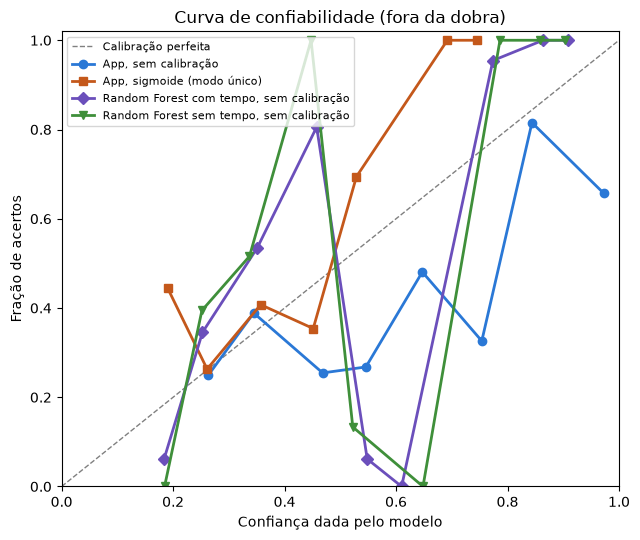

In [22]:
figura, eixo = plt.subplots(figsize=(6.5, 5.5))
eixo.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1, label='Calibração perfeita')
desenhar = [
      (NOME_APP + ', sem calibração', 'o', '#2a78d6', 'App, sem calibração')
    , (NOME_APP + ', sigmoide, modo único', 's', '#c4581b', 'App, sigmoide (modo único)')
    , (ml.FLORESTA + ' (com contexto temporal)', 'D', '#6b4fbb', 'Random Forest com tempo, sem calibração')
    , (ml.FLORESTA + ' (sem contexto temporal)', 'v', '#3f8f3a', 'Random Forest sem tempo, sem calibração')
]
for nome, marcador, cor, legenda in desenhar:
    faixas = faixas_por_modelo[nome]
    eixo.plot(
          faixas['confianca_media']
        , faixas['acerto']
        , marker=marcador
        , color=cor
        , linewidth=2
        , label=legenda
    )
eixo.set_xlabel('Confiança dada pelo modelo')
eixo.set_ylabel('Fração de acertos')
eixo.set_xlim(0, 1)
eixo.set_ylim(0, 1.02)
eixo.set_title('Curva de confiabilidade (fora da dobra)')
eixo.legend(loc='upper left', fontsize=8)
figura.tight_layout()
plt.show()

### A confiança nas sugestões que o app mostra

O app só sugere para os lançamentos que as regras deixam "A classificar", e mostra **uma sugestão por estabelecimento** (a média das probabilidades dos lançamentos dele). A calibração que importa para o texto do app é essa, medida abaixo com a configuração do app, fora da dobra. O texto do app é montado com estes números (`ml.CALIBRACAO_SUGESTOES`); a trava falha se eles mudarem.

In [23]:
previsto_app, probabilidades_app = calibradas['sem calibração']
sem_regra = previsto_regras == ft.A_CLASSIFICAR
por_lancamento = {
      'confianca': round(float(probabilidades_app[sem_regra].max(axis=1).mean()), 3)
    , 'acerto': round(float((previsto_app[sem_regra] == y[sem_regra]).mean()), 3)
    , 'quantidade': int(sem_regra.sum())
}
tabela_media = pd.DataFrame(probabilidades_app[sem_regra], columns=CATEGORIAS_GABARITO)
tabela_media['chave'] = grupos[sem_regra]
media_por_estabelecimento = tabela_media.groupby('chave')[CATEGORIAS_GABARITO].mean()
verdade_sem_regra = verdade_estabelecimento.loc[media_por_estabelecimento.index]
por_estabelecimento = {
      'confianca': round(float(media_por_estabelecimento.max(axis=1).mean()), 3)
    , 'acerto': round(float((media_por_estabelecimento.idxmax(axis=1) == verdade_sem_regra).mean()), 3)
    , 'quantidade': int(len(media_por_estabelecimento))
}
print('Por lançamento sem regra:', por_lancamento)
print('Por estabelecimento sem regra (o que o app mostra):', por_estabelecimento)
print('No app (src/modelo.py):', ml.CALIBRACAO_SUGESTOES)
assert ml.CALIBRACAO_SUGESTOES == {'por_lancamento': por_lancamento, 'por_estabelecimento': por_estabelecimento}

Por lançamento sem regra: {'confianca': 0.634, 'acerto': 0.537, 'quantidade': 149}
Por estabelecimento sem regra (o que o app mostra): {'confianca': 0.565, 'acerto': 0.452, 'quantidade': 31}
No app (src/modelo.py): {'por_lancamento': {'confianca': 0.634, 'acerto': 0.537, 'quantidade': 149}, 'por_estabelecimento': {'confianca': 0.565, 'acerto': 0.452, 'quantidade': 31}}


## 12. Conclusão

Os números abaixo são gerados por este notebook (se os dados mudarem, eles mudam junto).

In [24]:
f1_regras = comparacao['Regras do app']['f1_macro']
f1_procedimento = comparacao['Regras + ' + NOME_PROCEDIMENTO]['f1_macro']
print(f"Classe mais comum: F1-macro {comparacao['Classe mais comum']['f1_macro'].mean():.3f}")
print(f'Regras sozinhas: F1-macro {f1_regras.mean():.3f} ± {f1_regras.std():.3f}')
print(f'Regras + modelo (seleção aninhada): F1-macro {f1_procedimento.mean():.3f} ± {f1_procedimento.std():.3f}')
print('Configuração do app:', ESCOLHA_APP)
for variante, (previsto, probabilidades) in calibradas.items():
    ece, brier, faixas = calibracao(previsto, probabilidades)
    print(f'Confiança {variante}: ECE {ece:.3f} | Brier {brier:.3f} | acurácia do modelo {(previsto == y).mean():.3f}')
print('Confiança nas sugestões, por estabelecimento:', ml.CALIBRACAO_SUGESTOES['por_estabelecimento'])

Classe mais comum: F1-macro 0.047
Regras sozinhas: F1-macro 0.726 ± 0.114
Regras + modelo (seleção aninhada): F1-macro 0.748 ± 0.171
Configuração do app: ('Regressão Logística', False, 100.0)
Confiança sem calibração: ECE 0.252 | Brier 0.721 | acurácia do modelo 0.504
Confiança sigmoide, modo conjunto: ECE 0.124 | Brier 0.721 | acurácia do modelo 0.444
Confiança sigmoide, modo único: ECE 0.071 | Brier 0.761 | acurácia do modelo 0.402
Confiança temperatura: ECE 0.329 | Brier 0.797 | acurácia do modelo 0.504
Confiança nas sugestões, por estabelecimento: {'confianca': 0.565, 'acerto': 0.452, 'quantidade': 31}


### Respostas às hipóteses

Critério de cada hipótese, definido antes de olhar a resposta desta célula, e calculado dobra a dobra (5 dobras agrupadas por estabelecimento):

1. **Acima do chute ingênuo:** cada um dos 4 modelos tem F1-macro maior que "classe mais comum" em todas as 5 dobras.
2. **Regras + modelo acima das regras:** o ganho de F1-macro da seleção aninhada sobre as regras é positivo em todas as 5 dobras. Ganho médio positivo com dobras negativas conta como "não confirmada", porque a variação entre dobras é maior que o ganho.
3. **Contexto temporal ajuda:** para cada modelo, a versão com tempo ganha da versão sem tempo em todas as 5 dobras.
4. **Confiança calibrada:** alguma das variantes da seção 11 tem ECE menor que a versão sem calibração **sem** baixar a acurácia do modelo. (Baixar o ECE trocando sugestões certas por erradas não serve ao usuário.)

In [25]:
def veredito(confirmada, detalhe):
    return ('CONFIRMADA' if confirmada else 'NÃO CONFIRMADA') + ' | ' + detalhe


f1_chute = comparacao['Classe mais comum']['f1_macro']
modelos_secao_4 = [nome for nome in resultados]
acima_do_chute = {nome: int((comparacao[nome]['f1_macro'] > f1_chute).sum()) for nome in modelos_secao_4}
print('H1:', veredito(all(vezes == DOBRAS for vezes in acima_do_chute.values()), f'dobras acima do chute, por modelo: {acima_do_chute}'))

ganho_regras = comparacao['Regras + ' + NOME_PROCEDIMENTO]['f1_macro'] - comparacao['Regras do app']['f1_macro']
print('H2:', veredito(
      bool((ganho_regras > 0).all())
    , f'ganho médio {ganho_regras.mean():+.3f} ± {ganho_regras.std():.3f}, positivo em {int((ganho_regras > 0).sum())} de {DOBRAS} dobras'
))

for tipo in [ml.LOGISTICA, ml.FLORESTA]:
    ganho_tempo = comparacao[tipo + ' (com contexto temporal)']['f1_macro'] - comparacao[tipo + ' (sem contexto temporal)']['f1_macro']
    print(f'H3 ({tipo}):', veredito(
          bool((ganho_tempo > 0).all())
        , f'diferença média {ganho_tempo.mean():+.3f} ± {ganho_tempo.std():.3f}, com tempo melhor em {int((ganho_tempo > 0).sum())} de {DOBRAS} dobras'
    ))

ece_bruto, brier_bruto, faixas_bruto = calibracao(*calibradas['sem calibração'])
acuracia_bruta = (calibradas['sem calibração'][0] == y).mean()
variantes_boas = []
for variante, (previsto, probabilidades) in calibradas.items():
    ece, brier, faixas = calibracao(previsto, probabilidades)
    if variante != 'sem calibração' and ece < ece_bruto and (previsto == y).mean() >= acuracia_bruta:
        variantes_boas.append(variante)
sugestoes = ml.CALIBRACAO_SUGESTOES['por_estabelecimento']
print('H4:', veredito(
      len(variantes_boas) > 0
    , f'sem calibração ECE {ece_bruto:.3f}; variantes que baixam o ECE sem perder acurácia: {variantes_boas or "nenhuma"}; '
    + f'nas sugestões do app a confiança média é {sugestoes["confianca"]:.0%} e o acerto {sugestoes["acerto"]:.0%}'
))

H1: CONFIRMADA | dobras acima do chute, por modelo: {'Regressão Logística (com contexto temporal)': 5, 'Regressão Logística (sem contexto temporal)': 5, 'Random Forest (com contexto temporal)': 5, 'Random Forest (sem contexto temporal)': 5}
H2: NÃO CONFIRMADA | ganho médio +0.022 ± 0.143, positivo em 3 de 5 dobras
H3 (Regressão Logística): NÃO CONFIRMADA | diferença média -0.034 ± 0.069, com tempo melhor em 2 de 5 dobras
H3 (Random Forest): NÃO CONFIRMADA | diferença média +0.032 ± 0.091, com tempo melhor em 3 de 5 dobras
H4: NÃO CONFIRMADA | sem calibração ECE 0.252; variantes que baixam o ECE sem perder acurácia: nenhuma; nas sugestões do app a confiança média é 56% e o acerto 45%


### O que isso quer dizer

- **H1** é o resultado mais firme: os dois tipos de modelo aprendem algo de verdade a partir do nome, do valor e da repetição dos gastos.
- **H2** é o que interessa ao app. Nos lançamentos que as regras deixam "A classificar" o modelo acerta cerca de metade (seção 7), o que é ganho real, porque ali as regras acertam 0%. No F1-macro geral, porém, o ganho varia muito de dobra para dobra: em algumas, as sugestões erradas espalham lançamentos por categorias pequenas e derrubam a precisão delas. Por isso o app só **sugere**; nada muda de categoria sem o usuário aceitar.
- **H3:** mesmo com um padrão de dia da semana colocado de propósito pelo gerador, o ganho do contexto temporal não aparece de forma consistente. O app usa o modelo sem contexto temporal porque foi o que o procedimento da seção 5 escolheu com todos os dados.
- **H4:** a confiança sem calibração é otimista. As correções testadas ou baixam o acerto (sigmoide) ou pioram o ECE (temperatura), então o app mostra a confiança sem calibração e diz ao usuário, com os números medidos acima, que ela tende a ser otimista.

### Limitações

- **Dados sintéticos.** As 13 faturas vêm de um gerador; o gabarito é perfeito e os nomes que as regras reconhecem nunca erram. Em faturas reais as regras erram às vezes e o rótulo do usuário pode ser inconsistente.
- **Poucos estabelecimentos.** São 88 estabelecimentos, dos quais 31 sem regra. Cada dobra testa uns 18; um estabelecimento a mais ou a menos muda bastante o F1-macro (por isso os desvios-padrão grandes).
- **Categorias pequenas.** Jogos, Lazer e Viagem têm poucos lançamentos; o F1-macro dá a elas o mesmo peso das grandes, o que amplia a variação.
- **O desenvolvimento olhou os dados.** Ver a seção 13: a escolha do modelo foi tirada de dentro do teste, mas as variáveis e o gerador foram ajustados vendo resultados. A nota é provavelmente um pouco otimista.
- **Sem horário.** O CSV do Nubank não traz hora da compra, então o contexto temporal se limita ao dia da semana e à posição no ciclo da fatura.
- **Calibração medida em poucos casos.** O número citado no app vem de 31 estabelecimentos; ele indica a direção (otimista), não um valor preciso.

## 13. Como este experimento foi feito (transparência)

O notebook passou por rodadas, e parte das decisões foi tomada **olhando as mesmas dobras de teste**:

1. **Primeira rodada:** sem a variável "valor repetido". Ela mostrou assinaturas sem regra sendo previstas como Transporte; a variável foi criada depois disso.
2. **Calibração:** a sigmoide piorou o acerto, e a temperatura foi testada em seguida.
3. **Revisão:** apontou que escolher o modelo pelas dobras de teste deixava a nota otimista (daí a seção 5) e que, com o dia sorteado ao acaso, o teste de contexto temporal não tinha como dar outro resultado (daí o padrão colocado no gerador).
4. **O gerador** (nomes, valores, frequências) também foi ajustado olhando as faturas que ele produzia.

Consequência: a seção 5 tira a escolha do modelo de dentro do teste, mas o desenho das variáveis e do gerador ainda foi influenciado pelos resultados. Uma avaliação totalmente limpa precisaria de dados novos, nunca vistos durante o desenvolvimento (por exemplo, faturas reais rotuladas por outras pessoas).